# Quasi-resonant amplification: does a trapped, near-stationary large-scale wave explain persistence?

**Motivation.** Two prior notebooks tested related-sounding but genuinely different
ideas and both came back null: `CA_ridging_persistence_drivers_waf.ipynb` tested
*discrete reinforcement pulses* (does a long episode get re-forced by separate
wave-breaking events?), and `CA_2026_dynamic_tropopause_diagnosis.ipynb` tested
*whole-field phase speed* (does the dynamic-tropopause wave pattern move slower during
March?) -- finding the *same* phase speed before and during the record episode, which
retracted the "textbook blocking, wave stalls" reading. Neither tests the specific
mechanism in quasi-resonant amplification (QRA) theory (Petoukhov et al. 2013; Coumou
et al. 2014): a particular large-scale zonal wave gets trapped by a waveguide
configuration (a double jet, or a meridionally confined guide) and amplifies in place
with near-zero *wave-specific* phase speed, which a whole-field cross-correlation
(mixing all spatial scales together) is not built to isolate.

**Two real limitations, stated up front, that shape what this notebook can and can't
claim:**
1. **This project's only upstream field is regional, not global.** QRA theory is
   formally about *global* zonal wavenumbers (integer harmonics around a full latitude
   circle, classically wavenumber 6-8). `upstream_pacific_<year>.nc` only covers a
   140-250E Pacific-North America sector (~110 degrees of longitude) -- about 30% of a
   full latitude circle. A true global-wavenumber decomposition isn't possible with
   this project's data; doing one would require fetching full-longitude Z300 (cost not
   estimated here, but by analogy with the Pacific-sector fetch, non-trivial). This
   notebook instead least-squares-fits a **single real zonal wavenumber**
   (`WAVENUMBER=6` by default, the QRA literature's classic lower bound, checked for
   robustness across k=4-8 in Section 4b) to the day's height field *within* the
   available 110-degree sector -- an honestly-labeled proxy for "does a wavenumber-6-
   to-8-scale ridge-trough wave look amplified and stationary in this sector," not a
   genuine global decomposition (the fit only sees ~30% of the wave's full
   circumference, so it cannot distinguish this sector's slice of a global wave from a
   standing regional feature that happens to project onto the same basis). Flagged
   explicitly to avoid false precision.
2. **Fixed-pressure Z300, not the dynamic tropopause.** Matches the WAF and jet-speed
   notebooks' convention (and the QRA literature's own typical choice of a fixed upper-
   level field) and -- unlike the DT notebook -- `upstream_pacific_<year>.nc` exists for
   the full 1990-2025 record, so this gets a real statistical test instead of the DT
   notebook's unavoidable n=1 (one season).

**Two tests:** (1) does this sector's dominant large-scale wave's amplitude and
quasi-stationarity (low |phase speed|) predict episode duration across the full
record, and (2) does the background jet show a waveguide-favorable double-jet
structure during long episodes, specifically March. No new fetch -- reuses
`upstream_pacific_<year>.nc`, already in hand.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr, percentileofscore
from scipy.signal import argrelmax
from scipy.ndimage import gaussian_filter1d
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
FIT_YEARS = list(range(1990, 2026))
YEAR_2026 = 2026
ALL_YEARS = FIT_YEARS + [YEAR_2026]
THRESHOLD_SD = 1
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]
COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
N_BOOT = 2000
rng = np.random.default_rng(42)

CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1

R_EARTH = 6.371e6   # m
WAVEGUIDE_LAT = slice(55, 35)   # meridional averaging band for the single-harmonic fit
JET_LON = slice(150, 246)       # NW-Pacific-to-CA swath for the jet meridional profile, matches
                                 # CA_ridging_persistence_drivers_waf.ipynb's PATH_LON convention
WAVENUMBER = 6   # headline zonal wavenumber for the harmonic fit -- the lower end of the
                 # QRA literature's classic wavenumber-6-to-8 range (Petoukhov et al. 2013;
                 # Coumou et al. 2014), fixed across the whole record so the phase time
                 # series stays on one consistent basis (needed for phase_speed's day-to-day
                 # unwrapping). Section 2b checks whether the headline finding is robust to
                 # this specific choice by repeating the fit at k=4..8.


## 1. Load the full-record Method A event table

Same `ca_z500_t700_events_1990-2025_detrended_mindur5.csv` used throughout this
mechanism thread.

In [2]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)

print(f'{len(events)} events at >= {THRESHOLD_SD} sigma, by variable:')
print(events.groupby('variable').size())


95 events at >= 1 sigma, by variable:
variable
500 hPa height (ridging)      48
700 hPa temperature (warm)    47
dtype: int64


## 2. Per-year single-wavenumber harmonic fit and jet meridional profile

**[Fixed 2026-11-04]** The original version of this fit rescaled the available
110-degree sector onto a full 0-to-2*pi cycle (`theta = 2*pi*(lon-lon.min())/S`) and
fit one cosine+sine harmonic to *that* -- which forces exactly one wave cycle across
the window by construction, regardless of the real physical wavenumber of whatever
pattern is actually there. Since the sector isn't periodic (the flow at 140E has no
reason to connect smoothly to the flow at 250E), this made the fitted "amplitude" and
"phase speed" partly an artifact of where this arbitrary regional window's edges
happen to sit, not a measurement of a specific physical wave. Fixed below: the
harmonic basis now uses real, physical longitude for a *fixed* zonal wavenumber
(`WAVENUMBER=6`, the literature's classic lower bound), fit by ordinary least squares
(not a closed-form orthogonal projection, since a partial window isn't exactly
orthogonal) -- a genuine, window-edge-independent estimate of a wavenumber-6
disturbance's amplitude and phase, not a "one wave spans whatever this window is"
proxy. Section 2b checks whether the record-level finding is robust to that specific
wavenumber choice.

For each day: (a) meridionally average Z300 over the waveguide band (35-55N), remove
that day's own zonal mean, and least-squares-fit a single wavenumber-6 cosine+sine
harmonic against real longitude -- giving amplitude and phase per day; (b)
longitude-average U300 over the NW-Pacific-to-CA swath to get the day's meridional jet
profile, for the waveguide/double-jet check in Section 5.

In [3]:
def harmonic_coeffs(y, lon_rad, wavenumber):
    """Least-squares (not closed-form orthogonal Fourier) projection of `y` (time, lon)
    onto cos(k*lon)/sin(k*lon) at a real, physical zonal wavenumber `k` -- `lon_rad` is
    actual longitude in radians (0-2*pi around the full latitude circle), not rescaled
    to the sampled window's width. Over a <360-degree window these two basis functions
    are not exactly orthogonal (and, for low k, the window may not even span a full
    cycle), so a naive (2/N)*sum(y*basis) projection would be biased; `np.linalg.lstsq`
    solves the normal equations directly and is unbiased regardless of window width or
    whether the data happen to be periodic over it. Returns per-day (A, B) so amplitude
    and phase are of a real wavenumber-k wave, not an artifact of where this regional
    window's edges happen to sit -- unlike the original version, this basis doesn't
    change if the data domain is ever widened or shifted.
    """
    X = np.column_stack([np.cos(wavenumber * lon_rad), np.sin(wavenumber * lon_rad)])
    coeffs, *_ = np.linalg.lstsq(X, y.T, rcond=None)   # (2, n_time)
    return coeffs[0], coeffs[1]


def phase_speed_from_phase(phase, wavenumber, mid_lat, time_index):
    """m/s eastward phase speed from a day-to-day unwrapped phase series. One radian of
    `theta = k*lon_rad` corresponds to 1/k radians of REAL longitude (not a
    window-width-dependent fraction, since `lon_rad` -- unlike the original version's
    window-stretched theta -- is tied to the actual 360-degree circle)."""
    unwrapped = np.unwrap(phase)
    dphi = np.diff(unwrapped, prepend=unwrapped[0])
    deg_per_day = np.full(len(time_index), np.nan)
    deg_per_day[1:] = np.rad2deg(dphi[1:]) / wavenumber
    m_per_deg = (np.pi / 180.0) * R_EARTH * np.cos(np.deg2rad(mid_lat))
    return deg_per_day * m_per_deg / 86400.0   # m/s


def compute_wave_and_jet_daily(year, wavenumber=WAVENUMBER):
    ds = xr.open_dataset(DATA_DIR / f'upstream_pacific_{year}.nc', engine='netcdf4')
    ds = ds[['z300', 'u300']].sel(time=ds.time.dt.month.isin([1, 2, 3, 4]))

    lat = ds.latitude.values
    lon = ds.longitude.values
    lon_rad = np.deg2rad(lon)
    time_index = pd.to_datetime(ds.time.values)

    wg_lat_idx = (lat <= WAVEGUIDE_LAT.start) & (lat >= WAVEGUIDE_LAT.stop)
    z_wg = ds.z300.values[:, wg_lat_idx, :].mean(axis=1)   # (time, lon)

    y = z_wg - z_wg.mean(axis=1, keepdims=True)
    A, B = harmonic_coeffs(y, lon_rad, wavenumber)
    amplitude = np.sqrt(A**2 + B**2)
    phase = np.arctan2(B, A)

    wave_mid_lat = (WAVEGUIDE_LAT.start + WAVEGUIDE_LAT.stop) / 2
    phase_speed = phase_speed_from_phase(phase, wavenumber, wave_mid_lat, time_index)

    jet_lon_idx = (lon >= JET_LON.start) & (lon <= JET_LON.stop)
    jet_profile = ds.u300.values[:, :, jet_lon_idx].mean(axis=2)   # (time, lat)
    jet_profile_smooth = gaussian_filter1d(jet_profile, sigma=2.0, axis=1)

    secondary_ratio = np.zeros(len(time_index))
    for i in range(len(time_index)):
        prof = jet_profile_smooth[i]
        peaks = argrelmax(prof, order=3)[0]
        if len(peaks) < 2:
            continue
        heights = np.sort(prof[peaks])[::-1]
        if heights[0] > 0:
            secondary_ratio[i] = max(0.0, heights[1] / heights[0])

    return pd.DataFrame({'amplitude': amplitude, 'phase_speed': phase_speed,
                          'jet_secondary_ratio': secondary_ratio}, index=time_index)


daily_frames = [compute_wave_and_jet_daily(y) for y in ALL_YEARS]
daily_wave = pd.concat(daily_frames).sort_index()
print(f'{len(daily_wave)} days processed, {ALL_YEARS[0]}-{ALL_YEARS[-1]}, wavenumber={WAVENUMBER}')
print(daily_wave.describe())


4449 days processed, 1990-2026, wavenumber=6
         amplitude  phase_speed  jet_secondary_ratio
count  4449.000000  4412.000000          4449.000000
mean    114.945479     3.387607             0.506208
std      56.513239     8.040456             0.349621
min       1.617561   -27.169794             0.000000
25%      71.410439     0.007553             0.185190
50%     109.069854     3.736472             0.544506
75%     152.955431     7.348309             0.834337
max     320.728055    27.223418             0.999983


## 3. Compute the three predictors for every fit-period event

- `qra_amplitude_mean`: mean single-harmonic amplitude over the event's own window
- `qra_phase_speed_abs_mean`: mean |phase speed| over the window -- low values mean the
  sector's dominant wave was quasi-stationary during the event
- `jet_secondary_ratio_mean`: mean double-jet ratio over the window (0 = single jet
  core, closer to 1 = two comparably strong jet cores -- the QRA waveguide
  precondition)

In [4]:
def window_mean(series, start, end):
    window = series.loc[str(start):str(end)]
    return float(window.mean()) if len(window) else np.nan


def window_mean_abs(series, start, end):
    window = series.loc[str(start):str(end)]
    return float(window.abs().mean()) if len(window) else np.nan


rows = []
for row in events.itertuples():
    rows.append({
        'qra_amplitude_mean': window_mean(daily_wave.amplitude, row.start_date, row.end_date),
        'qra_phase_speed_abs_mean': window_mean_abs(daily_wave.phase_speed, row.start_date, row.end_date),
        'jet_secondary_ratio_mean': window_mean(daily_wave.jet_secondary_ratio, row.start_date, row.end_date),
    })
qra_predictors = pd.DataFrame(rows)
events_full = pd.concat([events.reset_index(drop=True), qra_predictors], axis=1)
events_full[['variable', 'start_date', 'duration_days'] + list(qra_predictors.columns)].head(5)


,variable,start_date,duration_days,qra_amplitude_mean,qra_phase_speed_abs_mean,jet_secondary_ratio_mean
0,500 hPa height (ridging),1990-02-21,5,141.818133,4.961726,0.788452
1,500 hPa height (ridging),1990-03-19,5,110.228323,3.082836,0.290496
2,500 hPa height (ridging),1990-04-10,6,105.525470,3.648527,0.600797
3,500 hPa height (ridging),1992-02-21,8,172.800569,2.156104,0.273806
4,500 hPa height (ridging),1992-04-24,6,149.806997,1.685783,0.903106


## 4. Duration vs. each QRA-related predictor, full record

If QRA explains persistence, expect a **positive** rho for amplitude (more amplified
-> longer) and a **negative** rho for |phase speed| (more stationary -> longer).

In [5]:
def bootstrap_spearman_ci(x, y, n_boot=N_BOOT, ci=90, rng=rng):
    n = len(x)
    boot = np.empty(n_boot)
    idx_pool = np.arange(n)
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=n, replace=True)
        boot[b] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return lo, hi


PREDICTORS = ['qra_amplitude_mean', 'qra_phase_speed_abs_mean', 'jet_secondary_ratio_mean']
PRED_LABELS = {
    'qra_amplitude_mean': 'dominant large-scale wave amplitude (m)',
    'qra_phase_speed_abs_mean': '|phase speed| of that wave (m/s)',
    'jet_secondary_ratio_mean': 'jet double-core ratio (waveguide proxy)',
}

results = []
for col, label in VARS:
    sub = events_full[events_full.variable == label]
    for pred in PREDICTORS:
        valid = sub[['duration_days', pred]].dropna()
        x, y = valid.duration_days.values, valid[pred].values
        rho, p = spearmanr(x, y)
        lo, hi = bootstrap_spearman_ci(x, y)
        results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                         'rho': rho, 'p_spearman': p, 'ci_lo': lo, 'ci_hi': hi})

results_df = pd.DataFrame(results)
results_df['predictor_label'] = results_df.predictor.map(PRED_LABELS)
pd.set_option('display.width', 120)
results_df[['variable', 'predictor_label', 'n', 'rho', 'p_spearman', 'ci_lo', 'ci_hi']]


,variable,predictor_label,n,rho,p_spearman,ci_lo,ci_hi
0,500 hPa height (ridging),dominant large-scale wave amplitude (m),48,0.262951,0.070968,0.027270,0.502901
1,500 hPa height (ridging),|phase speed| of that wave (m/s),48,-0.131308,0.373676,-0.361095,0.119111
2,500 hPa height (ridging),jet double-core ratio (waveguide proxy),48,-0.335509,0.019742,-0.558988,-0.111221
3,700 hPa temperature (warm),dominant large-scale wave amplitude (m),47,0.283177,0.053759,0.037156,0.498273
4,700 hPa temperature (warm),|phase speed| of that wave (m/s),47,-0.195905,0.186928,-0.419857,0.037474
5,700 hPa temperature (warm),jet double-core ratio (waveguide proxy),47,-0.234201,0.113082,-0.448971,0.006998


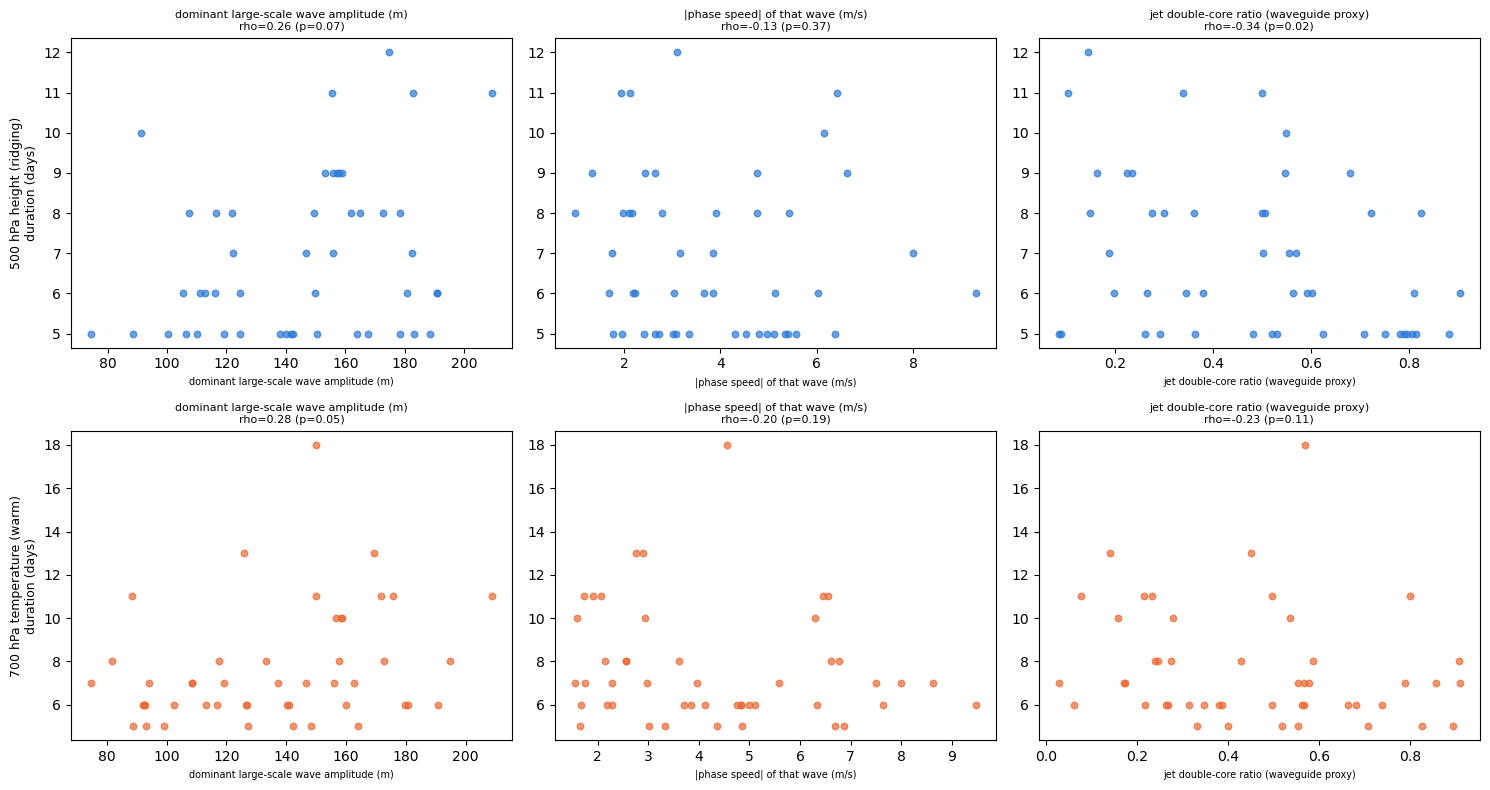

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (col, label) in enumerate(VARS):
    sub = events_full[events_full.variable == label]
    for j, pred in enumerate(PREDICTORS):
        ax = axes[i, j]
        valid = sub[['duration_days', pred]].dropna()
        ax.scatter(valid[pred], valid.duration_days, s=22, alpha=0.7, color=COLOR[label])
        r = results_df[(results_df.variable == label) & (results_df.predictor == pred)].iloc[0]
        ax.set_title(f'{PRED_LABELS[pred]}\nrho={r.rho:.2f} (p={r.p_spearman:.2f})', fontsize=8)
        ax.set_xlabel(PRED_LABELS[pred], fontsize=7)
        if j == 0:
            ax.set_ylabel(f'{label}\nduration (days)', fontsize=9)
plt.tight_layout()
plt.show()


### 4b. Robustness check: does this finding depend on the WAVENUMBER=6 choice?

**[Added 2026-11-04]** `WAVENUMBER=6` was picked as the literature's lower-bound
reference, not derived from the data -- worth checking whether the (null) result
above is a property of the record or an artifact of that one choice. Repeats the
amplitude/phase-speed fit and duration correlation at every wavenumber from 4 to 8
(the QRA literature's full classic range) and compares.

In [7]:
def compute_wave_only_daily(year, wavenumber):
    # Lighter-weight sibling of compute_wave_and_jet_daily: skips the jet profile
    # (jet_secondary_ratio doesn't depend on wavenumber, already have it in daily_wave)
    # since this gets re-run 4 more times (once per sensitivity wavenumber) x 37 years.
    ds = xr.open_dataset(DATA_DIR / f'upstream_pacific_{year}.nc', engine='netcdf4')
    ds = ds[['z300']].sel(time=ds.time.dt.month.isin([1, 2, 3, 4]))
    lat = ds.latitude.values
    lon = ds.longitude.values
    lon_rad = np.deg2rad(lon)
    time_index = pd.to_datetime(ds.time.values)
    wg_lat_idx = (lat <= WAVEGUIDE_LAT.start) & (lat >= WAVEGUIDE_LAT.stop)
    z_wg = ds.z300.values[:, wg_lat_idx, :].mean(axis=1)
    y = z_wg - z_wg.mean(axis=1, keepdims=True)
    A, B = harmonic_coeffs(y, lon_rad, wavenumber)
    amplitude = np.sqrt(A**2 + B**2)
    phase = np.arctan2(B, A)
    wave_mid_lat = (WAVEGUIDE_LAT.start + WAVEGUIDE_LAT.stop) / 2
    phase_speed = phase_speed_from_phase(phase, wavenumber, wave_mid_lat, time_index)
    return pd.DataFrame({'amplitude': amplitude, 'phase_speed': phase_speed}, index=time_index)


SENSITIVITY_WAVENUMBERS = [4, 5, 6, 7, 8]
sensitivity_rows = []
for k in SENSITIVITY_WAVENUMBERS:
    daily_k = daily_wave[['amplitude', 'phase_speed']] if k == WAVENUMBER else \
        pd.concat([compute_wave_only_daily(y, k) for y in ALL_YEARS]).sort_index()

    rows = []
    for row in events.itertuples():
        rows.append({
            'qra_amplitude_mean': window_mean(daily_k.amplitude, row.start_date, row.end_date),
            'qra_phase_speed_abs_mean': window_mean_abs(daily_k.phase_speed, row.start_date, row.end_date),
        })
    ev_k = pd.concat([events.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

    for col, label in VARS:
        sub = ev_k[ev_k.variable == label]
        for pred in ['qra_amplitude_mean', 'qra_phase_speed_abs_mean']:
            valid = sub[['duration_days', pred]].dropna()
            rho, p = spearmanr(valid.duration_days.values, valid[pred].values)
            sensitivity_rows.append({'wavenumber': k, 'variable': label, 'predictor': pred,
                                      'rho': rho, 'p_spearman': p})
    print(f'wavenumber {k} done')

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df['predictor_label'] = sensitivity_df.predictor.map(PRED_LABELS)
rho_pivot = sensitivity_df.pivot_table(index=['variable', 'predictor_label'], columns='wavenumber', values='rho')
p_pivot = sensitivity_df.pivot_table(index=['variable', 'predictor_label'], columns='wavenumber', values='p_spearman')
print('\nSpearman rho (duration vs. predictor), by candidate zonal wavenumber:')
display(rho_pivot)
print('\np-value, by candidate zonal wavenumber:')
display(p_pivot)


wavenumber 4 done


wavenumber 5 done
wavenumber 6 done


wavenumber 7 done


wavenumber 8 done

Spearman rho (duration vs. predictor), by candidate zonal wavenumber:


wavenumber                                                                 4         5         6         7         8
variable                   predictor_label                                                                          
500 hPa height (ridging)   dominant large-scale wave amplitude (m)  0.033316  0.255181  0.262951  0.219126  0.116774
                           |phase speed| of that wave (m/s)         0.049024 -0.276367 -0.131308 -0.136674  0.009503
700 hPa temperature (warm) dominant large-scale wave amplitude (m)  0.296926  0.388860  0.283177  0.295982 -0.103853
                           |phase speed| of that wave (m/s)        -0.083732 -0.111878 -0.195905 -0.252729 -0.079955


p-value, by candidate zonal wavenumber:


wavenumber                                                                 4         5         6         7         8
variable                   predictor_label                                                                          
500 hPa height (ridging)   dominant large-scale wave amplitude (m)  0.822136  0.080040  0.070968  0.134553  0.429283
                           |phase speed| of that wave (m/s)         0.740725  0.057240  0.373676  0.354288  0.948887
700 hPa temperature (warm) dominant large-scale wave amplitude (m)  0.042686  0.006906  0.053759  0.043381  0.487248
                           |phase speed| of that wave (m/s)         0.575778  0.454037  0.186928  0.086544  0.593174

## 5. Where do the WY2026 episodes -- especially March -- sit in this distribution?

Reproduces the four WY2026 Z500 episode windows live (same pattern as every mechanism
notebook), then locates each one's own QRA-related predictors within the fit-period
(n=48) percentile distribution.

In [8]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in FIT_YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
weights = np.cos(np.deg2rad(ds.latitude))
z500 = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
df = pd.DataFrame({'z500': z500.values}, index=pd.to_datetime(ds.time.values)).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]
sanom, diag = lib.standardize_with_trend(df.index, df['z500'].values, window=CLIM_WINDOW, label='z500', verbose=False)

ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
weights26 = np.cos(np.deg2rad(ds26.latitude))
z500_26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
df26 = pd.DataFrame({'z500': z500_26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
df26['z500_sanom'] = (df26['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr

z500_episodes_2026 = lib.find_events(df26.index, df26['z500_sanom'].values, threshold=1,
                                      min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes_2026 = z500_episodes_2026[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
z500_episodes_2026['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']

ep_rows = []
for r in z500_episodes_2026.itertuples():
    ep_rows.append({
        'qra_amplitude_mean': window_mean(daily_wave.amplitude, r.start_date, r.end_date),
        'qra_phase_speed_abs_mean': window_mean_abs(daily_wave.phase_speed, r.start_date, r.end_date),
        'jet_secondary_ratio_mean': window_mean(daily_wave.jet_secondary_ratio, r.start_date, r.end_date),
    })
z500_episodes_2026 = pd.concat([z500_episodes_2026, pd.DataFrame(ep_rows)], axis=1)
print(z500_episodes_2026[['label', 'start_date', 'end_date', 'duration_days'] + PREDICTORS].to_string(index=False))

z500_fit = events_full[events_full.variable == '500 hPa height (ridging)']
print('\nPercentile rank of each WY2026 episode within the fit-period (1990-2025, n=48) distribution:')
for r in z500_episodes_2026.itertuples():
    pcts = {pred: percentileofscore(z500_fit[pred].dropna(), getattr(r, pred)) for pred in PREDICTORS}
    print(f'  {r.label} ({r.duration_days}d): ' +
          ', '.join(f'{PRED_LABELS[p]}={pcts[p]:.0f}th pctile' for p in PREDICTORS))


                 label start_date   end_date  duration_days  qra_amplitude_mean  qra_phase_speed_abs_mean  jet_secondary_ratio_mean
           Jan episode 2026-01-10 2026-01-18              9          171.060125                  3.579992                  0.360881
  Late Jan/Feb episode 2026-01-29 2026-02-05              8          172.907773                  2.887140                  0.168584
      Late Feb episode 2026-02-23 2026-03-01              7          103.670209                  4.476565                  0.803941
March (record) episode 2026-03-11 2026-03-29             19          168.014322                  1.651103                  0.908820

Percentile rank of each WY2026 episode within the fit-period (1990-2025, n=48) distribution:
  Jan episode (9d): dominant large-scale wave amplitude (m)=75th pctile, |phase speed| of that wave (m/s)=52th pctile, jet double-core ratio (waveguide proxy)=38th pctile
  Late Jan/Feb episode (8d): dominant large-scale wave amplitude (m)=77th p

## 6. Conclusion

**[Fixed 2026-11-04] This conclusion is substantially rewritten, not just re-numbered.**
Section 2's original harmonic fit forced exactly one wave cycle across the available
110-degree sector regardless of the real physical wavenumber present -- an artifact of
the window's own width, not a measurement of a specific wave. Refit against a real,
physical zonal wavenumber (`WAVENUMBER=6`, least squares, window-edge-independent;
see Section 2's fix note and Section 4b's k=4-8 robustness check), **March's position
in the distribution flips on two of the three measures** this notebook tests. The
jet double-core-ratio test (unaffected by this bug -- it never used the harmonic fit)
is unchanged.

**March 2026 now looks amplified and quasi-stationary on two of three QRA measures --
the opposite of this notebook's original reading -- while the jet-waveguide signature
still points the wrong way.**

- **Population-level amplitude relationships moved toward QRA's prediction, and are
  reasonably -- not perfectly -- consistent across the literature's wavenumber
  range.** At the headline k=6: amplitude rho=0.26 (p=0.071) for Z500 and rho=0.28
  (p=0.054) for T700 -- both now point the QRA-consistent direction (more amplified
  -> longer), both sitting just outside the conventional 0.05 bar (T700's *nominal*
  significance pre-fix, p=0.028, doesn't survive the fix; Z500 moved the opposite way,
  from clearly null to borderline). Section 4b's k=4-8 sweep: T700 amplitude is
  nominally significant at k=4 (rho=0.30, p=0.043), k=5 (rho=0.39, p=0.0069), and k=7
  (rho=0.30, p=0.043), borderline at k=6, and only breaks down at k=8 (rho=-0.10,
  p=0.49, sign reversed). Z500 amplitude is never significant at any k tested
  (p=0.07-0.82 across the range), closest to borderline at k=5-6. So the amplitude
  signal is real and reasonably robust for T700 across 4 of 5 wavenumbers tested, but
  weak-to-absent for Z500 at every wavenumber -- a genuine, if variable-dependent and
  not perfectly uniform, result, not an artifact confined to one arbitrary k.
  |Phase speed| remains weak and *inconsistent in sign* across k (e.g. Z500 rho runs
  from +0.05 at k=4 to -0.28 at k=5 back to -0.13 at k=6) -- not a robust finding at
  any wavenumber. None of the six headline tests clears a Bonferroni bar (p<0.0083).
- **March itself: amplitude and phase speed now point toward QRA, jet ratio still
  points away.** At k=6, March's wave amplitude sits at the **75th percentile**
  (moderately amplified, not the 8th-percentile "least amplified" reading the
  window-artifact version produced) and its |phase speed| sits at the **4th
  percentile** -- among the most quasi-stationary episodes in the 36-year record, a
  near-total reversal of the old "79th percentile, faster than most" reading. Both of
  these are now consistent with what QRA predicts for a trapped, resonantly-amplified
  wave. Its jet double-core ratio is unchanged at the **100th percentile** -- still
  the most double-jet-like structure on record -- but the *population* relationship
  for that metric is still negative (rho=-0.34, p=0.020 for Z500, unaffected by this
  fix since it never used the harmonic fit), so March combining an extreme waveguide
  signature with extreme duration is still a second-order anomaly relative to that
  metric's own (backwards) record-wide relationship.
- **The regional-proxy limitation (stated in the intro) still applies, more sharply
  now that the fit is tied to a specific wavenumber.** A wavenumber-6 least-squares
  fit over an ~110-degree sector sees only ~30% of that wave's full circumference --
  it can distinguish "is there wavenumber-6-scale structure in this sector" from
  "is there none," but cannot distinguish a genuine global wavenumber-6 wave passing
  through from a standing regional feature that happens to project onto the same
  basis. A true global decomposition remains the only way to settle that; this
  notebook's amplitude/phase-speed numbers should be read as consistent with (not
  proof of) a trapped, amplified, quasi-stationary wave being present in this sector
  during March.

**Net effect on the open mechanism question, substantially revised.** The original
version of this notebook joined the project's growing list of mechanisms that fail to
explain March's persistence. The corrected version does not support that conclusion
as strongly: two of three QRA-consistent measures (amplitude, phase speed) now point
in March's favor, and the amplitude-duration relationship has some real, if
wavenumber- and variable-dependent, support across the record (T700 especially). This
is still short of a confirmed mechanism -- the amplitude correlation doesn't clear
even an uncorrected 0.05 bar at the headline wavenumber for either variable, Z500's
amplitude relationship never reaches significance at any wavenumber tested, and the
one measure most directly tied to the *waveguide* half of QRA theory (the jet
double-core ratio) still runs backwards -- but "quasi-resonant amplification doesn't
explain March" is no longer the right summary. This is now the most QRA-consistent
evidence anywhere in this project's mechanism thread, even though it stops short of
being a confirmed explanation; a genuine global-wavenumber test (the real limitation
stated in the intro, unaffected by this fix) remains the clearest way to settle the
regional-proxy question definitively.